# Example of preprocessing and feature extraction (Oonk et al. 2023)

This notebook will guide you through the methods used to get the features for the paper of Oonk et al. (2023). Since the raw data is privacy sensative, an open tracking data dataset is used to illustrate the methods. The open dataset can be found [here](https://github.com/MatKempeGroningen/WCSF_SolutionRoom). This dataset was provide for the World Congress on Science and Football 2023 Solution Room at the University of Groningen. Note that this dataset is already preprocessed, but to show the complete workflow, this notebook will handle it as if it was not preprocessed yet. 

Note: This package is purely for open science purposes, an optimized and more elaborate version of how to analyse soccer tracking and event data can be found in the [databallpy package](https://github.com/Alek050/databallpy/).

## Step 0: Reformatting the Data
Normally, this step is not necessary, or can be seens as loading in the raw data, but since this dataset is already preprocessed it is done for now. The goal of this step is to get a dataframe of positions that is equal to when the raw data is loaded in. In this case, we need information about the ball, the timing, and the players. The following columns are computed:
- `ball_x`, `ball_y`: representing the x and y location of the ball on the pitch.
- `ball_status`: can be either `alive` or `dead`, indicating whether the game was active or not.
- `ball_possession`: can be either `home` or `away`, indicating which team had possession of the ball
- `period`: can be either `1` or `2`, indicates if it is the first or second half of the match.
- `seconds`: the number of seconds that have been played in the match.
- `f"{side}_{player_id}_{metric}"`: `side` can be either `home` or `away`. `player_id` is a unique numeric id for the implied player. `metric` can be `x` or `y`, but after preprocessing also `vx` or `ay` indicating the velocity in x direction and the acceleration in y direction. The metrics `velocity` and `acceleration` give the magnitude of the velocity and acceleration without a direction. Note that, although given, this will be overwritten in the preprocessing of the data since specific filters are insisted.

Note: The `x` and `y` coordinates are in meters. The `x` represents the length of the pitch, while the `y` represents the width of the pitch. The coordinate (0, 0) is the center of the pitch, thus, (-52.5, -34.0) is the location of the bottom left corner flag and (52.5, 34.0) the top right corner flag. 

The precise code for reformatting the data can be found in `scripts/reformat_positions.py`. For now I will just show how the dataframe looks like after reformatting.

In [76]:
import pandas as pd

reformatted_positions = pd.read_csv("data/reformated_positions.csv", index_col=0)
print(reformatted_positions.columns[:10])
print(reformatted_positions.iloc[:, :10].info())

Index(['ball_x', 'ball_y', 'ball_status', 'ball_possession', 'period',
       'seconds', 'home_888778_x', 'home_888778_y', 'home_888778_velocity',
       'home_888778_acceleration'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 57374 entries, 0 to 57373
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ball_x                    57374 non-null  float64
 1   ball_y                    57374 non-null  float64
 2   ball_status               57374 non-null  object 
 3   ball_possession           57374 non-null  object 
 4   period                    57374 non-null  int64  
 5   seconds                   57374 non-null  float64
 6   home_888778_x             57374 non-null  float64
 7   home_888778_y             57374 non-null  float64
 8   home_888778_velocity      57374 non-null  float64
 9   home_888778_acceleration  57374 non-null  float64
dtypes: float64(7), int64(1), o

## Step 1: Preprocessing the Data

Preprocessing of the data has several steps included.
1. Represent the home team playing from left to right and the away team from right to left for the whole match.
2. Filter the ball data with a savitzky-golay filter.
3. Compute the velocity and acceleration of each player.
4. Obtain individual player possessions and duels using the methodology of Vidal-Codina et al (2022).

The full code can be found in `scripts/preprocess_tracking_data.py`

Note: This data is already preprocessed, thus it makes little sence to filter it again. This is just an example of how it was done with the raw data. 
Note: This data is only 10 frames per second. The raw data used in the Oonk et al. (2023) paper was 25 frames per second.

In [77]:
from scripts.preprocess_tracking_data import (
    normalize_playing_direction_tracking_data, filter_data, differentiate, get_player_possessions_and_duels
)

Fs = 10

# make a copy of the tracking data to not overwrite the original
processed_positions = reformatted_positions.copy()

# represent the home team as playing from left to right and the
# away team as playing from right to left for the full match
processed_positions = normalize_playing_direction_tracking_data(processed_positions)

# filter the ball data
processed_positions[["ball_x", "ball_y"]] = filter_data(
    processed_positions[["ball_x", "ball_y"]],
    filter_type="savitzky_golay",
    window_length=7,
    polyorder=2,
)

# compute the velocity and acceleration of each player
processed_positions = differentiate(
    processed_positions,
    metric="",  # no prefix so differentiate just the x and y values
    new_name="velocity",
    filter_type="savitzky_golay",
    window=7,
    poly_order=2,
    Fs=Fs,
    max_val=12,  # maximum speed of 12 m/s for each player
)
processed_positions = differentiate(
    processed_positions,
    metric="v",  # differentiate the velocities
    new_name="acceleration",
    filter_type="savitzky_golay",
    window=25,
    poly_order=2,
    Fs=Fs,
    max_val=7,  # maximum accleration of 7 m/s/s for each player
)

# compute the individual ball possessions and duels
possession_duels = get_player_possessions_and_duels(
    processed_positions, pz_radius=1.5, dz_radius=1.5
)
processed_positions["player_possession"] = possession_duels[0]
processed_positions["duels"] = possession_duels[1]

Index(['ball_x', 'ball_y', 'ball_status', 'ball_possession', 'period',
       'seconds', 'home_888778_x', 'home_888778_y', 'home_888778_velocity',
       'home_888778_acceleration',
       ...
       'away_53615_ax', 'away_53615_ay', 'away_897104_ax', 'away_897104_ay',
       'away_28307_ax', 'away_28307_ay', 'away_895772_ax', 'away_895772_ay',
       'player_possession', 'duels'],
      dtype='object', length=230)
14           None
15           None
16    away_893441
17    away_893441
18    away_893441
19    away_893441
20    away_893441
21    away_893441
22    away_893441
23    away_893441
24    away_893441
Name: player_possession, dtype: object


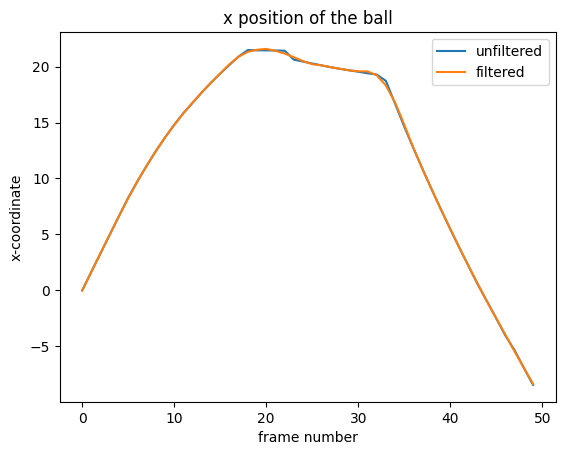

In [78]:
import matplotlib.pyplot as plt

print(processed_positions.columns)
print(processed_positions.loc[14:24, "player_possession"])

plt.plot(reformatted_positions["ball_x"].iloc[:50]* -1, label="unfiltered")
plt.plot(processed_positions["ball_x"].iloc[:50], label="filtered")
plt.title("x position of the ball")
plt.xlabel("frame number")
plt.ylabel("x-coordinate")
plt.legend()
plt.show()


As you can see, for every player a `vx`, `vy`, `ax`, and `ay` are added, representing the velocity and acceleration in x and y direcitons. On top of that, the total magnitude of the velocity and acceleration is recalculated and stored in `acceleration` and `velocity` for every player. 

Also, the individual player possessions are added in the `player_possession` column. It indicates what individual player has possession of the ball. In this case, the player with player id 893441 obtains possession of the ball in frame 16. This is calculated using the methodology of Vidal-Codina et al. (2022). 

Lastly, the ball x and y coordinates are filtered. As mentioned before, since this dataset is already preprocessed, the effect is not that big, but for the raw data it would have been a valuable adjustment.

To give you a little more feel of the data, here are two frames:

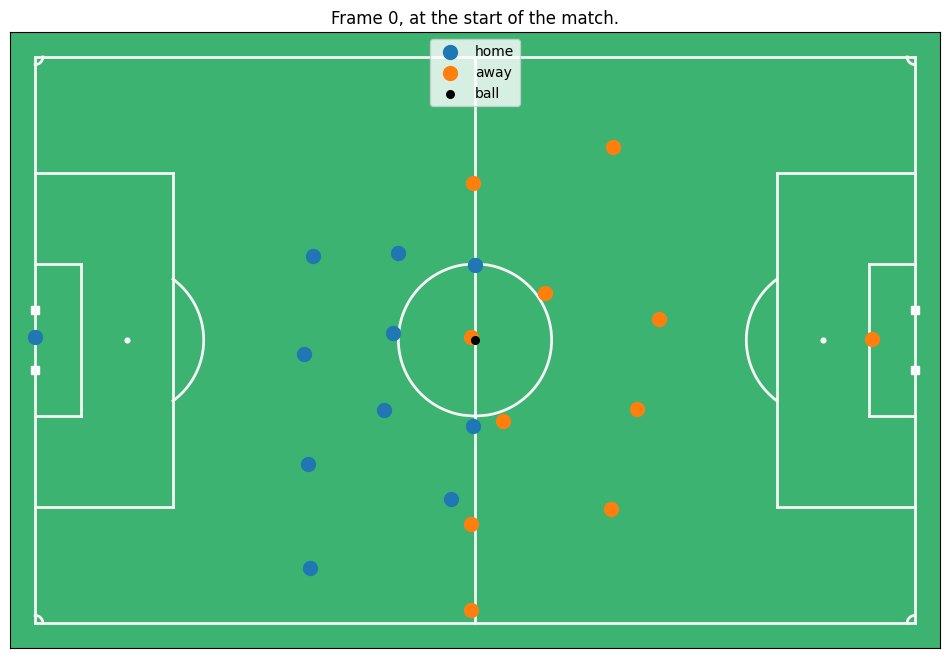

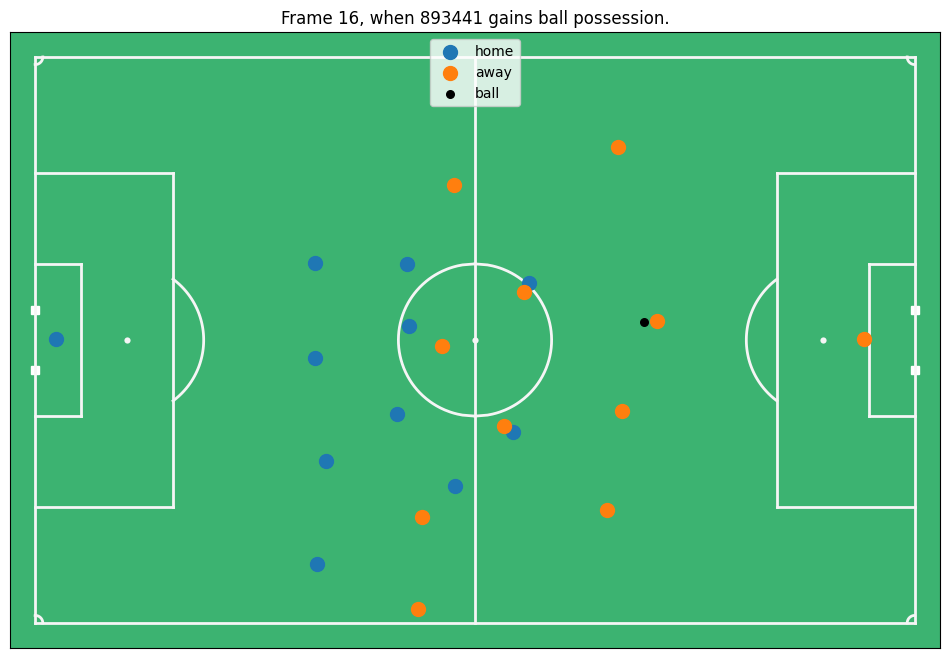

In [79]:
from databallpy.visualize import plot_soccer_pitch

frame0 = processed_positions.loc[0]
frame16 = processed_positions.loc[16]

def plot_frame(frame: pd.Series, title: str):
    home_players_x = [x for x in processed_positions.columns if x.startswith("home") and x.endswith("_x")]
    home_players_y = [x for x in processed_positions.columns if x.startswith("home") and x.endswith("_y")]
    away_players_x = [x for x in processed_positions.columns if x.startswith("away") and x.endswith("_x")]
    away_players_y = [x for x in processed_positions.columns if x.startswith("away") and x.endswith("_y")]
    
    fig, ax = plot_soccer_pitch(field_dimen=(105.0, 68.0))
    ax.scatter(frame[home_players_x], frame[home_players_y], label="home", s=100)
    ax.scatter(frame[away_players_x], frame[away_players_y], label="away", s=100)
    ax.scatter(frame["ball_x"], frame["ball_y"], label="ball", c="black", s=30)
    ax.legend(loc='upper center')
    ax.set_title(title)
    plt.show()

plot_frame(frame0, "Frame 0, at the start of the match.")
plot_frame(frame16, "Frame 16, when 893441 gains ball possession.")





## Step 2: Synchronising the 1-vs-1 actions.

Opta take-ons were synchronised with the tracking data. Since we have no corresponding open dataset of opta, we can only give an example of how it would have been with the real data from opta. Lets say opta indicated a take-on by player 894107 in at 65 minutes and 11 seconds with the x location begin 31.0 and the y location -16.0. We use the following cost function:

$cost=Δt^2+d_{ball-event}^2​+d_{player-event}^2​+d_{ball-player}^2​$ 

Where $Δt$ is the time difference between the take on and the tracking data frame in seconds, and $d$ is the distance in meters.

First, the frame where the time difference between the event and the tracking data = 0, lets call this $t_{0}$. The cost function is calculated for every frame where $t_{0} - 10s < t_{tracking data} < t_{0} + 10s$ where $s$ stands for seconds. The tracking data frame where the cost function is the lowest, is selected as optimal alignment.


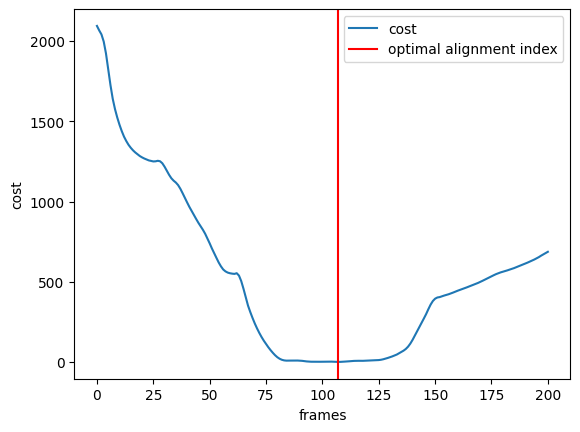

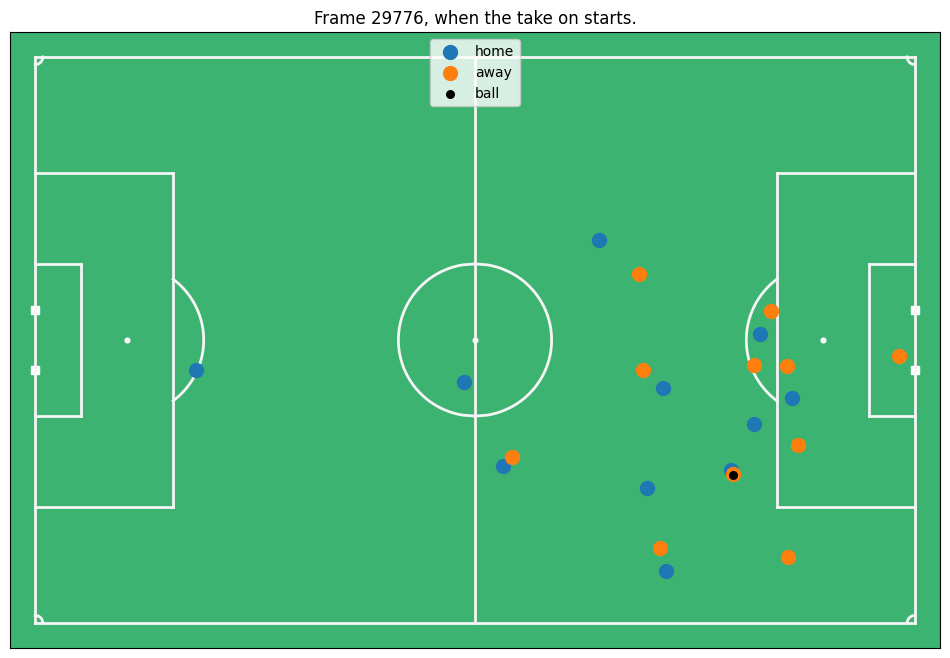

In [80]:
import numpy as np

t0 = 65*60 + 11
event_location = (31., -16.)

time_mask = (processed_positions["seconds"] >= t0 - 10) & (processed_positions["seconds"] <= t0 + 10)
potential_action_df = processed_positions.loc[time_mask]
attacker = "away_894107"

# initialize cost array
cost = np.zeros(len(potential_action_df))

# calculate time difference
time_diff = np.abs(potential_action_df["seconds"] - t0).values

# calculate event ball distance
ball_location = potential_action_df[["ball_x", "ball_y"]].values
ball_event_distance = np.linalg.norm(ball_location - event_location, axis=1)

# calculate player event distance
player_location = potential_action_df[[f"{attacker}_x", f"{attacker}_y"]].values
player_event_distance = np.linalg.norm(player_location - event_location, axis=1)

# calculate ball_player distance
ball_player_distance = np.linalg.norm(ball_location - player_location, axis=1)

# add everything to the cost function
cost = np.power(time_diff, 2) + np.power(ball_event_distance, 2) + np.power(player_event_distance, 2) + np.power(ball_player_distance, 2)
optimal_idx = np.argmin(cost)

plt.plot(cost, label="cost")
plt.axvline(x=optimal_idx, label="optimal alignment index", c="r")
plt.xlabel("frames")
plt.ylabel("cost")
plt.legend()
plt.show()

optimal_alignment_global_idx = optimal_idx + potential_action_df.index[0]
frame_start_take_on = potential_action_df.loc[optimal_alignment_global_idx]

plot_frame(frame_start_take_on, f"Frame {optimal_alignment_global_idx}, when the take on starts.")

Looking at the cost function plot and the frame, it seems like the synchronisation went well. In the cost function plot you can see that around frame 75 (2.5 seconds before the opta notated take-on) the cost values are getting very low, probably because the player obtains possession over the ball here and is therefore very close to the ball. 

Now that the optimal synchronisation has taken place, video data, with the same sample frequency as the tracking data, is used to manually assess the validity of the 1-vs-1 action and, if indeed valid, the successfulness of the action. For this example, lets continue by saying that it is indeed a valid 1-vs-1 action, and the action was successfull since the player gets awarded a free kick.

## Step 3: Defining the different phases

Now it is time to start thinking about the features of the 1-vs-1 action. However, we first need to distinguish between the different phases of the 1-vs-1 action. In the article, 3 phases are described:
- Possession phase: the phase where the attacker has possession of the ball, but is not yet in a duel
- Duel phase: the phase where the attacker and defender are in a duel (interpersonal distance < 1.5 meters)
- Full action phase: the total action, thus both the possession and duel phase are included here.



In [81]:
attacking_player = "away_894107"

possible_action_df = processed_positions.loc[optimal_alignment_global_idx-(5*Fs):optimal_alignment_global_idx+(5*Fs)].copy()
possible_action_df['duels'].fillna('', inplace=True)

# find the start and end of every phase
start_possession_idx = possible_action_df[possible_action_df["player_possession"] == attacking_player].first_valid_index()
start_duel_idx = possible_action_df[possible_action_df["duels"].str.contains("away_894107")].first_valid_index()
end_possession_idx = start_duel_idx - 1
duel = possible_action_df.loc[start_duel_idx, "duels"]
defending_player = duel.split("-")[0] if duel.split("-")[0] != attacking_player else duel.split("-")[1]
change_in_duel = np.where(possible_action_df.loc[start_duel_idx:, "duels"] != duel)[0][0]
end_duel_idx = start_duel_idx + change_in_duel

# create the dataframes for every phase
possession_phase_df = processed_positions.loc[start_possession_idx:end_possession_idx]
duel_phase_df = processed_positions.loc[start_duel_idx:end_duel_idx]
full_phase_df = processed_positions.loc[start_possession_idx:end_duel_idx]

print(f"The possession phase took {len(possession_phase_df) / Fs} seconds, the duel took {len(duel_phase_df) / Fs} seconds. Thus, the whole action took {len(full_phase_df) / Fs} seconds." )


The possession phase took 1.8 seconds, the duel took 1.6 seconds. Thus, the whole action took 3.4 seconds.


## Step 4: Feature extraction

Now that the different phases are created, we can start calculating the features for the 1-vs-1 action. Note that the success of the action is manually labeled and therefore not included here. Most of the features are not to difficult to compute, but for some of the features different functions were created. The functions can be found in the `scripts/` folder in this project.

In [82]:
from scripts.calculate_pressure import get_pressure_on_player
from scripts.calculate_voronoi_area import get_voronoi_area
from scripts.calculate_angles import get_angles
from scripts.calculate_features import get_max_speed_angle_interaction, get_angle_diff_in_metric

res_dict = {}
pitch_length = 105.
pitch_width = 68.

# individual factors
res_dict["max_acc_att_full_action"] = full_phase_df[f"{attacking_player}_acceleration"].max()
res_dict["max_acc_def_full_action"] = full_phase_df[f"{defending_player}_acceleration"].max()
res_dict["med_acc_att_full_action"] = full_phase_df[f"{attacking_player}_acceleration"].median()
res_dict["max_vel_att_full_action"] = full_phase_df[f"{attacking_player}_velocity"].max()
res_dict["max_vel_def_full_action"] = full_phase_df[f"{defending_player}_velocity"].max()

# environmental factors
goal_loc = np.array([pitch_length/2., 0]) if attacking_player.startswith("home") else np.array([-pitch_length/2., 0])
ball_loc_start_possession = np.array([possession_phase_df.iloc[0]["ball_x"], possession_phase_df.iloc[0]["ball_y"]])
ball_loc_start_duel = np.array([duel_phase_df.iloc[0]["ball_x"], duel_phase_df.iloc[0]["ball_y"]])
res_dict["dist_ball_goalline_start_possession"] = np.abs(goal_loc[0] - ball_loc_start_possession[0])
res_dict["dist_ball_goalline_start_duel"] = np.abs(goal_loc[0] - ball_loc_start_duel[0])
res_dict["dist_ball_sideline_start_possession"] = np.abs(pitch_width/2. - np.abs(ball_loc_start_possession[1]))
res_dict["dist_ball_sideline_start_duel"] = np.abs(pitch_width/2. - np.abs(ball_loc_start_duel[1]))

# interaction factors
attacker_position = full_phase_df.loc[:, [f"{attacking_player}_x", f"{attacking_player}_y"]]
defender_position = full_phase_df.loc[:, [f"{defending_player}_x", f"{defending_player}_y"]]
ball_position = full_phase_df.loc[:, ["ball_x", "ball_y"]]
dist_att_def = np.linalg.norm(attacker_position.values - defender_position.values, axis=1)
dist_att_ball = np.linalg.norm(attacker_position.values - ball_position.values, axis=1)
dist_def_ball = np.linalg.norm(defender_position.values - ball_position.values, axis=1)
pressure_duel = get_pressure_on_player(duel_phase_df, attacking_player, pitch_size=[pitch_length, pitch_width])
attacker_space = get_voronoi_area(full_phase_df.loc[start_duel_idx], attacking_player, field_dim=[pitch_length, pitch_width])
defender_space = get_voronoi_area(full_phase_df.loc[start_duel_idx], defending_player, field_dim=[pitch_length, pitch_width])
directional_change_att = np.arctan2(duel_phase_df[f"{attacking_player}_vy"]*duel_phase_df[f"{attacking_player}_ax"] - duel_phase_df[f"{attacking_player}_vx"]*duel_phase_df[f"{attacking_player}_ay"],
                                duel_phase_df[f"{attacking_player}_vy"]*duel_phase_df[f"{attacking_player}_ay"] + duel_phase_df[f"{attacking_player}_vx"]*duel_phase_df[f"{attacking_player}_ax"])
directional_change_att = np.rad2deg(directional_change_att)

res_dict["min_relative_distance_att_def"] = dist_att_def.min()
res_dict["std_relative_distance_att_def"] = dist_att_def.std()
res_dict["median_relative_distance_att_def"] = np.median(dist_att_def)
res_dict["std_relative_distance_att_ball"] = dist_att_ball.std()
res_dict["std_relative_distance_def_ball"] = dist_def_ball.std()
res_dict["min_relative_distance_def_ball"] = dist_def_ball.min()
res_dict["max_pressure_att_duel_phase"] = np.max(pressure_duel)
res_dict["max_relative_speed_difference_att_def_possession_phase"] = np.max(np.abs(possession_phase_df[f"{attacking_player}_velocity"] - possession_phase_df[f"{defending_player}_velocity"]))
res_dict["median_relative_speed_difference_att_def_full_action"] = np.median(np.abs(full_phase_df[f"{attacking_player}_velocity"] - full_phase_df[f"{defending_player}_velocity"]))
res_dict["max_relative_speed_difference_att_def_duel_phase"] = np.max(np.abs(duel_phase_df[f"{attacking_player}_velocity"] - duel_phase_df[f"{defending_player}_velocity"]))
res_dict["max_relative_moving_angle_att_def_duel_phase"] = get_angle_diff_in_metric(duel_phase_df, attacking_player, second=defending_player, metric="v", func=np.max)
res_dict["max_speed_angle_interaction_att_def_duel_phase"] = get_max_speed_angle_interaction(duel_phase_df, attacking_player, second=defending_player)
res_dict["action_space_start_duel"] = attacker_space + defender_space
res_dict["std_ball_att_std_ball_def_full_action"] = np.std(dist_att_ball) - np.std(dist_def_ball)
res_dict["median_directional_change_att_full_action"] = np.median(np.abs(directional_change_att))

# assign the outcome of the 1-vs-1 action
res_dict["outcome"] = 1

In [83]:
pd.Series(res_dict)

max_acc_att_full_action                                     6.499917
max_acc_def_full_action                                     6.855905
med_acc_att_full_action                                     4.330035
max_vel_att_full_action                                     4.627435
max_vel_def_full_action                                     6.555252
dist_ball_goalline_start_possession                        84.159047
dist_ball_goalline_start_duel                              83.753333
dist_ball_sideline_start_possession                        19.378571
dist_ball_sideline_start_duel                              16.838571
min_relative_distance_att_def                               0.360694
std_relative_distance_att_def                               4.541267
median_relative_distance_att_def                            2.009727
std_relative_distance_att_ball                              0.202368
std_relative_distance_def_ball                              4.552660
min_relative_distance_def_ball    